# Student Performance ML Project
End-to-end project on EDA, preprocessing, regression, and classification.

**step 1: import libraries**

In [51]:
# data handling
# model saving 
import joblib

# visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer

# regression models
# classification models
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge

# Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

**step 2: load dataset**

In [265]:
df = pd.read_csv('StudentsPerformance.csv')
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


**Step 3: Basic Information**

In [6]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [3]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


**Step 4: check missing values**

In [4]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

If missing values exist:

**`df.fillna(df.mode().iloc[0], inplace=True)`**

**Step 5: check duplicates**

In [7]:
df.duplicated().sum()

np.int64(0)

If duplicate value exist:

**`df.drop_duplicates(inplace=True)`**

**Step 6: outlier detection**

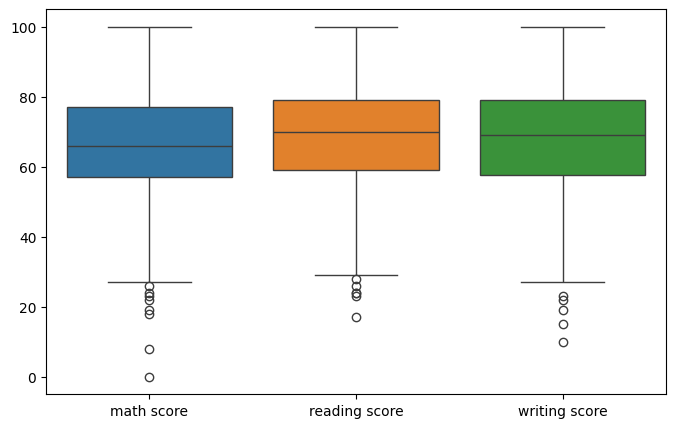

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(df[['math score','reading score', 'writing score']])
plt.show()

**IQR Method**

In [13]:
print('before shape: ',df.shape)

before shape:  (1000, 8)


In [266]:
# remove using iqr method
cols = ['math score', 'reading score', 'writing score']

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    # Cap values instead of dropping rows
    df[col] = df[col].clip(lower, upper)

# Your row count stays exactly the same, so your gender plot will work!
print("Rows remaining:", df.shape[0])


Rows remaining: 1000


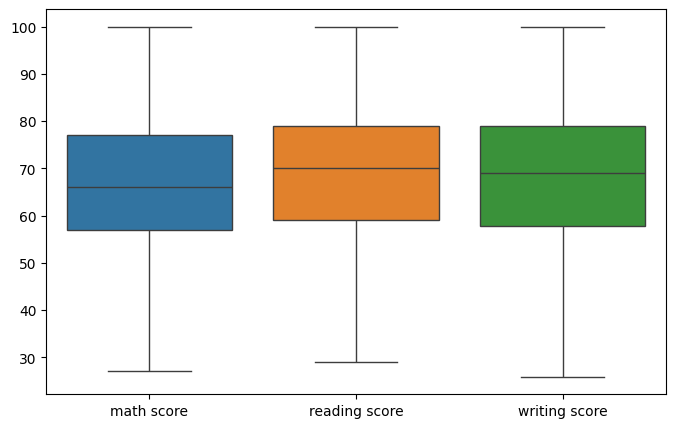

In [29]:
# check remove or not
plt.figure(figsize=(8,5))
sns.boxplot(df[['math score','reading score', 'writing score']])
plt.show()

**Step 7: EDA**

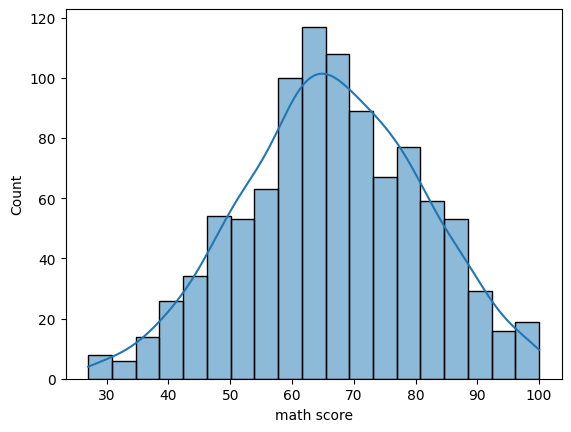

In [ ]:
# 1.Distribution

sns.histplot(df['math score'], kde=True)
plt.show()

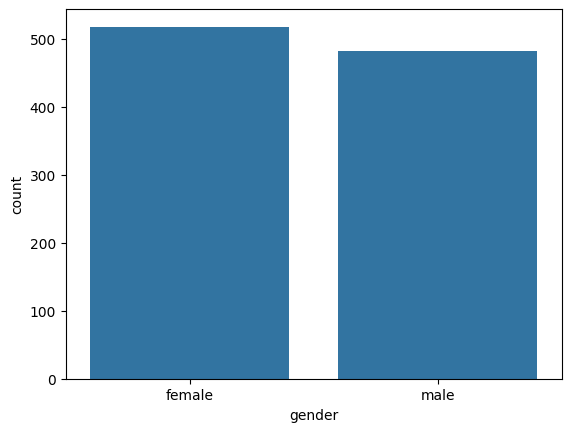

In [30]:
# 2.Count Plot

sns.countplot(x='gender', data=df)
plt.show()

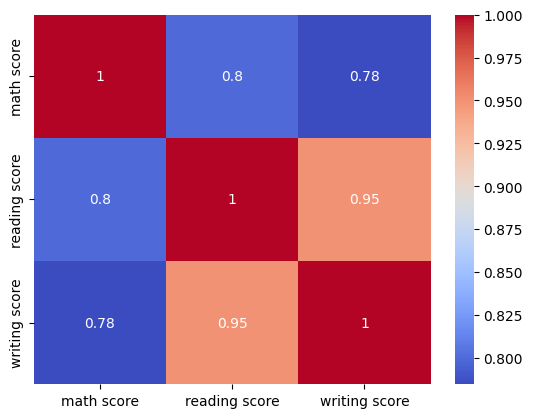

In [22]:
# 3.Correlation Heatmap
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True,
            cmap='coolwarm')
plt.show()

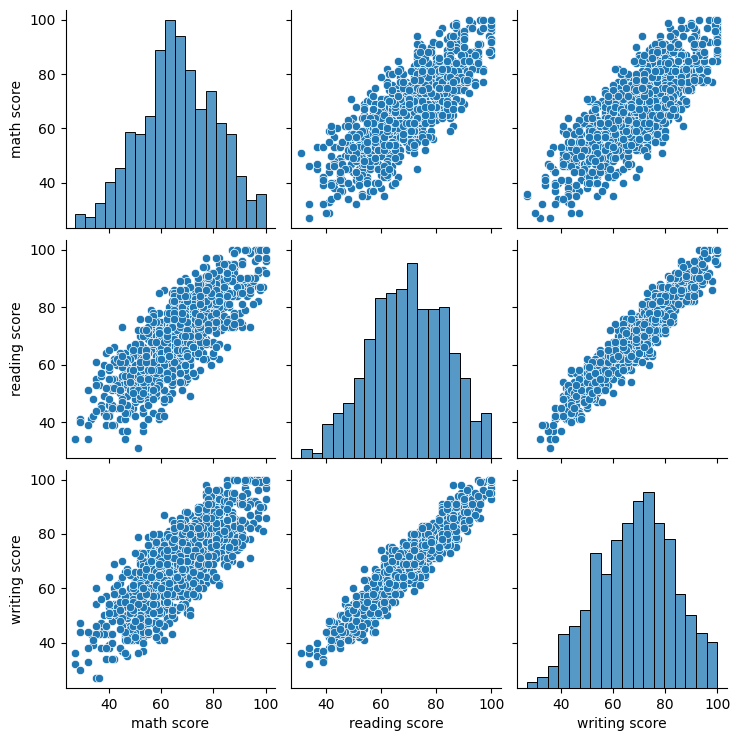

In [24]:
# 4.Pairplot

sns.pairplot(df[['math score','reading score', 'writing score']])
plt.show()

**step 8: Feature Engineering**

In [267]:
df['total_score']=(df['math score']+df['reading score']+df['writing score'])

df['average_score']=(df['math score']+df['reading score']+df['writing score'])/3

def performance(avg):
    if avg >= 80:
        return "Excellent"
    elif avg >= 60:
        return "Good"
    else:
        return "Poor"
# performance category
df['performance'] = df['average_score'].apply(performance)

#study effectiveness
df['prep_effective'] = (df['test preparation course'] == 'completed').astype(int)

In [269]:
# create pass/fail target
df['pass_fail']=np.where(df['math score']>=40,1,0)

**Step 9: encoding - no need this step because we use pipeline**

from sklearn.preprocessing import OrdinalEncoder

1. Identify your text columns
`text_cols = df.select_dtypes(include=['object', 'string']).columns`

2. Create ONE single encoder object for the entire dataset
`encoder = OrdinalEncoder()`

3. Fit and transform all text columns at once
`df[text_cols] = encoder.fit_transform(df[text_cols])`

Your text columns are now converted to numbers!
`print(df.head())`

**Step 9: Regression Problem**

In [270]:
#Predict Math Score
# Features & target
X = df.drop(['math score', 'pass_fail'], axis=1)   # Assuming math score is your target

y = df['math score']

**Step 11: preprocessing pipeline**

In [271]:
## Column selection

# numerical col
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# categorical col
cat_cols = X.select_dtypes(include=['object', 'string']).columns

# Pipelines
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num',num_transformer,num_cols),
    ('cat',cat_transformer,cat_cols)
])

#X = preprocessor.fit_transform(X)      #NEVER do this when using Pipeline:
#x_test = ct.transform(X_test)

**Step 11: Train Test Split**

In [272]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Step 12: Feature Scaling** - no need this we use in pipeline

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

**Step 12: Regression models**

**1. Linear regression**

In [274]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
y_pred = lr_pipeline.predict(X_test)

print("MAE:",mean_absolute_error(y_test, y_pred))
print("MSE:",mean_squared_error(y_test, y_pred))
print("R2:",r2_score(y_test, y_pred))

MAE: 7.720046824033489e-14
MSE: 7.549588189582336e-27
R2: 1.0


**2. Ridge Regression**

In [275]:
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])
ridge_pipeline.fit(X_train,y_train)
pred = ridge_pipeline.predict(X_test)

print("R2:",r2_score(y_test, pred))

R2: 0.9994822485739185


**3. Lasso Regression**

In [199]:
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=0.1))
])
lasso_pipeline.fit(X_train,y_train)
pred = lasso_pipeline.predict(X_test)

print("R2:",r2_score(y_test, pred))

R2: 0.993690878989177


**4. Decision Tree Regressor**

In [200]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',DecisionTreeRegressor(random_state=42))
])
tree_pipeline.fit(X_train,y_train)
pred = tree_pipeline.predict(X_test)

print("R2:",r2_score(y_test, pred))

R2: 0.9286793378162728


**5. Random Forest Regressor**

In [201]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',RandomForestRegressor(n_estimators=100,random_state=42))
])
rf_pipeline.fit(X_train,y_train)
pred = rf_pipeline.predict(X_test)

print("R2:",r2_score(y_test, pred))

R2: 0.9647517020984342


**6. Gradient Boosting Regressor**

In [239]:
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',GradientBoostingRegressor())
])
gb_pipeline.fit(X_train,y_train)
pred = gb_pipeline.predict(X_test)

print("R2:",r2_score(y_test, pred))

R2: 0.8554587163782718


**Step 13: Classification Problem**

In [277]:
#Predict Pass / Fail

X = df.drop('pass_fail', axis=1)
y = df['pass_fail']

In [278]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'string']).columns

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

**Step 14: Train Test Split**

In [279]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Step 15: Scaling**

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

**Step 15: classification models**

**1. Logistic regression**

In [280]:
log_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression())
])
log_pipeline.fit(X_train,y_train)
pred = log_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 0.995


**2. KNN**

In [281]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])
knn_pipeline.fit(X_train,y_train)
pred = knn_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 0.99


**3. Decision Tree Classifier**

In [282]:
dtc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier())
])
dtc_pipeline.fit(X_train, y_train)
pred = dtc_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 1.0


**4. Random Forest Classifier**

In [283]:
rfc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',RandomForestClassifier())
])

rfc_pipeline.fit(X_train,y_train)
pred = rfc_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 1.0


**5. SVM**

In [284]:
svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC())
])
svm_pipeline.fit(X_train,y_train)
pred = svm_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 0.995


**6. Naive Bayes**

In [285]:
nb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GaussianNB())
])
nb_pipeline.fit(X_train, y_train)
pred = nb_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 0.76


**7. Gradient Boosting Classifier**

In [286]:
gbc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier())
])
gbc_pipeline.fit(X_train, y_train)
pred = gbc_pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test, pred))

Accuracy: 1.0


In [287]:
print('classification_report: ',classification_report(y_test,pred,zero_division=True))

classification_report:                precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      1.00      1.00       189

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



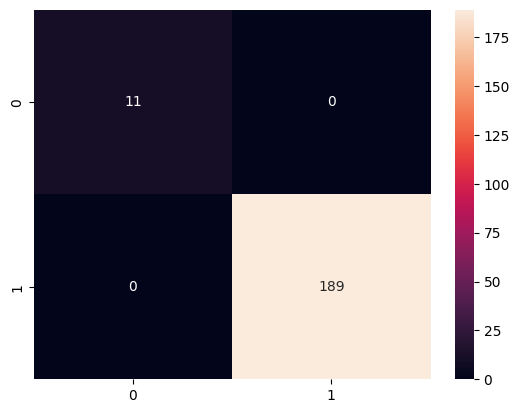

In [288]:
# Confusion Matrix

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm,annot=True,fmt='d')
plt.show()

**Feature Selection**

**Feature Importance:**

In [292]:
#Get trained model from pipeline
rf_model = rf_pipeline.named_steps['model']

#Get feature names from preprocessor
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

#Create feature importance table
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

print(importance.sort_values(by='Importance', ascending=False))

                                              Feature  Importance
3                                  num__average_score    0.464832
2                                    num__total_score    0.413933
6                                    cat__gender_male    0.033505
5                                  cat__gender_female    0.032335
0                                  num__reading score    0.021663
1                                  num__writing score    0.015827
11                        cat__race/ethnicity_group E    0.001785
16      cat__parental level of education_some college    0.001447
18                            cat__lunch_free/reduced    0.001399
10                        cat__race/ethnicity_group D    0.001287
22                         cat__performance_Excellent    0.001283
12  cat__parental level of education_associate's d...    0.001221
19                                cat__lunch_standard    0.001177
9                         cat__race/ethnicity_group C    0.001086
14       c

**Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor())
])

params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10]
}


rf_grid = GridSearchCV(
    pipeline,
    params,
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print('best_params: ',rf_grid.best_params_)
print('\nbest_score: ',rf_grid.best_score_)

best_params:  {'model__max_depth': 5, 'model__n_estimators': 200}

best_score:  0.9999951240022892


**Pipeline**

In [ ]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor())
])

pipeline.fit(X_train, y_train)

**Save Model**

In [ ]:
joblib.dump(
    pipeline,
    'student_model.pkl'
)

['student_model.pkl']

**Load Model**

In [298]:
model = joblib.load(
    'student_model.pkl'
)

In [ ]:
prediction = rf_grid.predict(X_test)
print(prediction[:5])

[1. 1. 1. 1. 1.]


`Easy Flow to Remember`

1. Import Libraries
2. Load Dataset
3. Basic Information/Understand Data
Data Cleaning
4. Missing Values
5. Duplicates
6. Outliers
7. EDA
8. Feature Engineering
9. Encoding
10. Scaling
11. Train-Test Split
12. Regression Models
13. Regression Metrics
14. Classification Models
15. Classification Metrics
16. Feature Selection
17. Hyperparameter Tuning
18. Pipeline
19. Save Model
20. Deployment (Streamlit)

[1. Import Libraries] ➔ [2. Load Dataset] ➔ [3. Understand Data]
                               │
                ┌──────────────┴──────────────┐
     [4, 5, 6. Data Cleaning]           [7. EDA] (Visualize, explore)
 (Drop rows, fix structural errors)           │
                │                             ▼
                ▼                      [8. Feature Engineering]
   [11. Train-Test Split]              (Create new raw columns)
                │
                ▼
┌───────────────────────────────────────────────────────┐
│ 🚀 THE PIPELINE BEGINS HERE (Steps 4, 9, 10, 16, 12/14) │
│                                                        │
│  ├─► Numerical Transformer: [4. Impute] ➔ [6. Outliers] ➔ [10. Scale]
│  ├─► Categorical Transformer: [4. Impute] ➔ [9. Encode]
│  │
│  ├─► ColumnTransformer (Merges features back together)
│  │
│  ├─► [16. Feature Selection] (Optional step inside pipeline)
│  │
│  └─► [12/14. Model] (Regression or Classification)      │
└────────────────────────────────────────────────────────┘
                               │
                               ▼
            [13/15. Evaluate Metrics] & [17. Tuning]
                               │
                               ▼
                       [18. Save Pipeline] 
                               │
                               ▼
                 [19. Deploy to Streamlit]
            (Load pipeline ➔ Feed raw user input)